# Module 4 Homework — Trading Strategy and Simulation

**Stock Markets Analytics Zoomcamp 2026 (DataTalks.Club)**

This notebook solves [Homework 4](https://github.com/DataTalksClub/stock-markets-analytics-zoomcamp/blob/main/cohorts/2026/homework4.md).
It reproduces the modelling and simulation steps of the course notebook
[`[2026]_Module_04_Colab_Trading_Simulations.ipynb`](https://github.com/DataTalksClub/stock-markets-analytics-zoomcamp/blob/main/04-trading-strategy-and-simulation/%5B2026%5D_Module_04_Colab_Trading_Simulations.ipynb),
but wraps them into one function, `run_experiment()`, so that every homework setup runs from a clean state
in a single notebook instead of three separate copies.

| Experiment | Categorical features for dummies | Target: `is_positive_growth_30d_future = 1` if | Extra Random Forest rules | Answers |
|---|---|---|---|---|
| `baseline` | Month, Weekday, Ticker, ticker_type, month_wom | `growth_future_30d > 1` | — | sanity check vs. the lecture |
| `q1_q2` | Month, Weekday, ticker_type | `growth_future_30d > 1` | thresholds 0.56 … 0.64 | Q1, Q2 |
| `q3` | Month, Weekday, Ticker, ticker_type, month_wom | `growth_future_30d > 1.022` | — | Q3 |

Adding extra threshold rules does not change any other predictor, so Q1 and Q2 share one run.

**What is reproduced exactly:** feature sets and their order, dummies, temporal split (70/15/15), manual rules `pred0`–`pred4`,
Decision Trees (`max_depth` 10, 4, 7), Random Forest (`max_depth=13`, `n_estimators=100`), all with `random_state=42`,
the threshold rules `pred8`–`pred11`, and the `sim1` simulation ($100 per signal, 30-day holding period, 0.2% fees).
Hyperparameter tuning, Logistic Regression and the neural network are left out: they do not produce any predictor used in the simulation.

Runtime: roughly 10–15 minutes for all three experiments on a standard Colab CPU (longer on a 2-core Codespace).

## 0. Setup

In [1]:
# Dependencies (Colab has most of them; a fresh Codespace usually does not).
# nbformat is needed for plotly charts to render in VS Code / Jupyter.
%pip install -q seaborn plotly nbformat scikit-learn pyarrow gdown


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import sys
import gc
import time

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

### 0.1 Data

Pre-computed dataset from Module 2 (33 large US stocks, daily, with technical indicators, candlestick patterns and macro features),
shared by the course authors on Google Drive.

In [3]:
# Course dataset (Google Drive file shared in the Module 4 notebook).
# In this repo the same file is already used by Module 3, so reuse it if present;
# otherwise download it next to this notebook (it is git-ignored).
GDRIVE_FILE_ID = '1oQSUMCs2DyQQIh8Y62UhrT00cIsE9Sr5'
DATA_FILE = 'stocks_df_combined_2026_09_18.parquet.brotli'

candidates = [os.environ.get('HW4_DATA_PATH', ''), DATA_FILE, os.path.join('..', '03-modeling', DATA_FILE)]
DATA_PATH = next((p for p in candidates if p and os.path.exists(p)), DATA_FILE)
print(f'Data file: {DATA_PATH}')

if not os.path.exists(DATA_PATH):
    try:
        import gdown
    except ImportError:
        import subprocess
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'gdown'], check=True)
        import gdown
    gdown.download(id=GDRIVE_FILE_ID, output=DATA_PATH, quiet=False)

df_full = pd.read_parquet(DATA_PATH)
print(df_full.shape)

Data file: ../03-modeling/stocks_df_combined_2026_09_18.parquet.brotli
(240759, 203)


### 0.2 Feature sets

Same definitions and the same column order as in the course notebook.
The order matters: the Random Forest samples features by position, so a different order would give a slightly different forest.

In [4]:
# growth indicators (past growth only, no future growth)
GROWTH = [g for g in df_full.keys() if (g.find('growth_') == 0) & (g.find('future') < 0)]

OHLCV = ['Open', 'High', 'Low', 'Close_x', 'Volume']

# target-related columns (never used as features)
TO_PREDICT = [g for g in df_full.keys() if g.find('future') >= 0]

# custom numerical features
df_full['ln_volume'] = df_full.Volume.apply(lambda x: np.log(x + 1e-6))
df_full['div_payout'] = (df_full.Dividends > 0).astype(int)
df_full['stock_split'] = (df_full['Stock Splits'] > 0).astype(int)
CUSTOM_NUMERICAL = ['SMA10', 'SMA20', 'growing_moving_average', 'high_minus_low_relative',
                    'volatility', 'ln_volume', 'div_payout', 'stock_split']

# TA-Lib indicators: https://github.com/TA-Lib/ta-lib-python/blob/master/docs/funcs.md
TECHNICAL_INDICATORS = ['adx', 'adxr', 'apo', 'aroon_1', 'aroon_2', 'aroonosc',
 'bop', 'cci', 'cmo', 'dx', 'macd', 'macdsignal', 'macdhist', 'macd_ext',
 'macdsignal_ext', 'macdhist_ext', 'macd_fix', 'macdsignal_fix',
 'macdhist_fix', 'mfi', 'minus_di', 'mom', 'plus_di', 'dm', 'ppo',
 'roc', 'rocp', 'rocr', 'rocr100', 'rsi', 'slowk', 'slowd', 'fastk',
 'fastd', 'fastk_rsi', 'fastd_rsi', 'trix', 'ultosc', 'willr',
 'ad', 'adosc', 'obv', 'atr', 'natr', 'ht_dcperiod', 'ht_dcphase',
 'ht_phasor_inphase', 'ht_phasor_quadrature', 'ht_sine_sine', 'ht_sine_leadsine',
 'ht_trendmod', 'avgprice', 'medprice', 'typprice', 'wclprice']

TECHNICAL_PATTERNS = [g for g in df_full.keys() if g.find('cdl') >= 0]

MACRO = ['gdppot_us_yoy', 'gdppot_us_qoq', 'cpi_core_yoy', 'cpi_core_mom', 'FEDFUNDS',
         'DGS1', 'DGS5', 'DGS10']

NUMERICAL = GROWTH + TECHNICAL_INDICATORS + TECHNICAL_PATTERNS + CUSTOM_NUMERICAL + MACRO

TARGET = 'is_positive_growth_30d_future'

print(f'Numerical features: {len(NUMERICAL)} '
      f'(growth {len(GROWTH)}, indicators {len(TECHNICAL_INDICATORS)}, patterns {len(TECHNICAL_PATTERNS)}, '
      f'custom {len(CUSTOM_NUMERICAL)}, macro {len(MACRO)})')

Numerical features: 186 (growth 54, indicators 55, patterns 61, custom 8, macro 8)


## 1. Pipeline functions

Each function corresponds to a section of the course notebook. `run_experiment()` chains them for one configuration.

### 1.1 Data preparation: dummies, target, temporal split

In [5]:
CATEGORICAL_FULL = ['Month', 'Weekday', 'Ticker', 'ticker_type', 'month_wom']   # course setup (301 features)
CATEGORICAL_SHORT = ['Month', 'Weekday', 'ticker_type']                          # Q1 setup (208 features)


def temporal_split(df, train_prop=0.7, val_prop=0.15):
    # Splits by date into train / validation / test (same rule as in the course notebook)
    min_date, max_date = df.Date.min(), df.Date.max()
    total_days = (max_date - min_date).days
    train_end = min_date + pd.Timedelta(days=total_days * train_prop)
    val_end = train_end + pd.Timedelta(days=total_days * val_prop)
    df['split'] = np.select([df.Date <= train_end, df.Date <= val_end],
                            ['train', 'validation'], default='test')
    return df


def prepare_dataset(df_full, categorical, target_growth_threshold=1.0):
    # 25 years of data
    df = df_full[df_full.Date >= '2000-01-01'].copy()

    # Target: 1 if the stock grows more than the threshold over the next 30 trading days.
    # The course data defines it with threshold 1.0 (any growth); Q3 uses 1.022.
    if target_growth_threshold != 1.0:
        df[TARGET] = (df['growth_future_30d'] > target_growth_threshold).astype(int)

    # categorical columns as strings (month names, weekday numbers)
    df['Month'] = pd.to_datetime(df['Month'], format='%m').dt.strftime('%B')
    df['Weekday'] = df['Weekday'].astype(str)

    # month + week of month, e.g. 'January_w2'
    df['month_wom'] = df.Month + '_w' + df.Date.apply(lambda d: (d.day - 1) // 7 + 1).astype(str)

    dummy_variables = pd.get_dummies(df[categorical], dtype='int32')
    dummies = dummy_variables.keys().to_list()

    new_df = pd.concat([df, dummy_variables], axis=1)
    new_df = temporal_split(new_df)
    return new_df.copy(), dummies

### 1.2 Manual rule-of-thumb predictions (pred0–pred4)

In [6]:
def add_manual_predictions(new_df):
    new_df['pred0_manual_cci'] = (new_df.cci > 200).astype(int)
    new_df['pred1_manual_prev_g1'] = (new_df.growth_30d > 1).astype(int)
    new_df['pred2_manual_prev_g1_and_snp'] = ((new_df['growth_30d'] > 1) & (new_df['growth_snp500_30d'] > 1)).astype(int)
    new_df['pred3_manual_dgs10_5'] = ((new_df['DGS10'] <= 4.5) & (new_df['DGS5'] <= 4)).astype(int)
    new_df['pred4_manual_dgs10_fedfunds'] = ((new_df['DGS10'] > 4) & (new_df['FEDFUNDS'] <= 4.795)).astype(int)
    return new_df

### 1.3 Model matrices

Train on train + validation, predict on the whole dataset, evaluate on test, exactly as in the course.
`X_test` is kept unscaled here (see *Notes* at the end on the original notebook).

In [7]:
def clean_dataframe_from_inf_and_nan(df):
    # +-inf -> NaN, NaN -> 0
    df = df.replace([np.inf, -np.inf], np.nan)
    return df.fillna(0)


def build_matrices(new_df, features):
    train_valid = new_df.split.isin(['train', 'validation'])
    test = new_df.split == 'test'

    # float32 halves memory; tree models in scikit-learn convert inputs to float32 anyway,
    # so the fitted models and predictions are the same as with float64
    X_all = clean_dataframe_from_inf_and_nan(new_df[features]).astype('float32')
    return {
        'X_train_valid': X_all[train_valid],
        'y_train_valid': new_df.loc[train_valid, TARGET],
        'X_test': X_all[test],
        'y_test': new_df.loc[test, TARGET],
        'X_all': X_all,
    }

### 1.4 Models and decision rules (pred5–pred11, plus optional extra Random Forest rules)

In [8]:
RF_BEST_MAX_DEPTH = 13       # selected in the course (pre-computed tuning grid)
RF_BEST_N_ESTIMATORS = 100
DT_SECOND_BEST_DEPTH = 7     # 'second best' Decision Tree depth selected in the course


def fit_decision_tree(X, y, max_depth):
    clf = DecisionTreeClassifier(max_depth=max_depth, random_state=42)
    return clf.fit(X, y)


def add_model_predictions(new_df, m, extra_rf_thresholds=()):
    t0 = time.time()

    # Decision Trees (class labels, default threshold 0.5)
    clf_10 = fit_decision_tree(m['X_train_valid'], m['y_train_valid'], max_depth=10)
    new_df['pred5_clf_10'] = clf_10.predict(m['X_all'])

    clf_4 = fit_decision_tree(m['X_train_valid'], m['y_train_valid'], max_depth=4)
    new_df['pred6_clf_4'] = clf_4.predict(m['X_all'])

    clf_best = fit_decision_tree(m['X_train_valid'], m['y_train_valid'], max_depth=DT_SECOND_BEST_DEPTH)
    new_df['pred7_clf_second_best'] = clf_best.predict(m['X_all'])

    # Decision Tree (depth 7): custom thresholds on predicted probability
    proba_dt = clf_best.predict_proba(m['X_all'])[:, 1]
    new_df['pred8_clf_second_best_rule_56'] = (proba_dt >= 0.56).astype(int)
    new_df['pred9_clf_second_best_rule_66'] = (proba_dt >= 0.66).astype(int)
    print(f'  Decision Trees fitted ({time.time() - t0:.0f}s)')

    # Random Forest: custom thresholds on predicted probability
    rf_best = RandomForestClassifier(n_estimators=RF_BEST_N_ESTIMATORS,
                                     max_depth=RF_BEST_MAX_DEPTH,
                                     random_state=42,
                                     n_jobs=-1)
    rf_best.fit(m['X_train_valid'], m['y_train_valid'])
    proba_rf = rf_best.predict_proba(m['X_all'])[:, 1]
    new_df['pred10_rf_best_rule_55'] = (proba_rf >= 0.55).astype(int)
    new_df['pred11_rf_best_rule_65'] = (proba_rf >= 0.65).astype(int)

    # Extra Random Forest rules (Q2). Numbering continues after pred11: the numeric prefix
    # must be unique, because the simulation names its columns by it (e.g. 'sim1_net_rev_pred12').
    for i, t in enumerate(extra_rf_thresholds):
        new_df[f'pred{12 + i}_rf_best_rule_{round(t * 100)}'] = (proba_rf >= t).astype(int)
    print(f'  Random Forest fitted ({time.time() - t0:.0f}s)')

    models = {'clf_10': clf_10, 'clf_4': clf_4, 'clf_best': clf_best, 'rf_best': rf_best}
    return new_df, models

### 1.5 Threshold table (precision / recall / number of trades vs. threshold)

Same logic as `tpr_fpr_dataframe()` in the course. Decision rule: predict class 1 when `proba >= threshold`.
`tp + fp` is the number of trades the rule would make on the test set.

In [9]:
def tpr_fpr_dataframe(y_true, y_pred, only_even=False):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    thresholds = np.linspace(0, 1, 51 if only_even else 101)

    scores = []
    for t in thresholds:
        predict_positive = y_pred >= t
        tp = int((predict_positive & (y_true == 1)).sum())
        fp = int((predict_positive & (y_true == 0)).sum())
        fn = int((~predict_positive & (y_true == 1)).sum())
        tn = int((~predict_positive & (y_true == 0)).sum())

        precision = tp / (tp + fp) if tp + fp > 0 else np.nan
        recall = tp / (tp + fn) if tp + fn > 0 else np.nan
        f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else np.nan
        accuracy = (tp + tn) / (tp + tn + fp + fn)
        scores.append((round(t, 2), tp, fp, fn, tn, precision, recall, accuracy, f1))

    df_scores = pd.DataFrame(scores, columns=['threshold', 'tp', 'fp', 'fn', 'tn',
                                              'precision', 'recall', 'accuracy', 'f1_score'])
    df_scores['trades'] = df_scores.tp + df_scores.fp
    df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
    df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)
    return df_scores

### 1.6 Trading simulation `sim1`

Rule: invest **$100** in every positive prediction on the test set, sell after 30 trading days,
pay **0.1%** on buy and on sell (0.2% per round trip).

* `capital = 100 * 30 * Q75(daily trades)`: positions overlap for 30 days, and the 75th percentile of daily signals
  is used as a "busy but normal" day.
* `CAGR = ((capital + net_revenue) / capital) ** (1/4)`: the test period is about 4 years.

The formulas are copied from the course notebook. Precision on test is added for convenience.

In [10]:
def simulate_sim1(new_df, predictions):
    test = new_df[new_df.split == 'test']
    results = []

    for pred in predictions:
        positive = test[test[pred] == 1]
        count = len(positive)

        gross = (100 * (positive['growth_future_30d'] - 1)).sum()
        fees = -100 * 0.002 * count
        net = gross + fees

        daily_counts = positive.groupby('Date')[pred].count()
        avg_per_day = daily_counts.mean() if count > 0 else np.nan
        q75_per_day = daily_counts.quantile(0.75) if count > 0 else np.nan
        capital = 100 * 30 * q75_per_day
        cagr = ((capital + net) / capital) ** (1 / 4) if count > 0 else np.nan

        results.append({
            'prediction': pred,
            'precision_test': positive[TARGET].mean() if count > 0 else np.nan,
            'sim1_count_investments': count,
            'sim1_gross_rev': gross,
            'sim1_fees': fees,
            'sim1_net_rev': net,
            'sim1_fees_percentage': -fees / gross if gross > 0 else np.nan,
            'sim1_average_net_revenue': net / count if count > 0 else np.nan,
            'sim1_avg_investments_per_day': avg_per_day,
            'sim1_capital': capital,
            'sim1_CAGR': cagr,
        })

    df_res = pd.DataFrame(results)
    df_res['sim1_growth_capital_4y'] = (df_res.sim1_net_rev + df_res.sim1_capital) / df_res.sim1_capital
    return df_res


def bubble_chart(df_res, title):
    fig = px.scatter(df_res.dropna(subset=['sim1_CAGR']),
                     x='sim1_avg_investments_per_day', y='sim1_CAGR',
                     size='sim1_growth_capital_4y', text='prediction',
                     title=title, height=600,
                     labels={'sim1_avg_investments_per_day': 'Average investments per day',
                             'sim1_CAGR': 'CAGR (test, ~4 years)'})
    fig.update_traces(textposition='top center')
    fig.show()

### 1.7 One experiment end to end

In [11]:
def run_experiment(name, categorical, target_growth_threshold=1.0, extra_rf_thresholds=()):
    print(f'=== Experiment: {name} ===')
    t0 = time.time()

    new_df, dummies = prepare_dataset(df_full, categorical, target_growth_threshold)
    features = NUMERICAL + dummies
    print(f'  Features: {len(features)} (numerical {len(NUMERICAL)} + dummies {len(dummies)})')
    print(f'  Share of class 1 in the target: {new_df[TARGET].mean():.3f}')

    new_df = add_manual_predictions(new_df)
    m = build_matrices(new_df, features)
    new_df, models = add_model_predictions(new_df, m, extra_rf_thresholds)

    predictions = [k for k in new_df.keys() if k.startswith('pred')]
    sim = simulate_sim1(new_df, predictions)
    # keep only what the answers need: Random Forest probabilities on test (for the Q2 threshold table)
    rf_proba_test = models['rf_best'].predict_proba(m['X_test'])[:, 1]
    result = {'name': name, 'n_features': len(features), 'sim': sim,
              'rf_proba_test': rf_proba_test, 'y_test': m['y_test'].to_numpy()}

    # free the large objects before the next experiment (a 2-core Codespace has 8 GB of RAM)
    del new_df, m, models
    gc.collect()
    print(f'  Done in {time.time() - t0:.0f}s')
    return result


SIM_COLUMNS = ['prediction', 'precision_test', 'sim1_count_investments', 'sim1_avg_investments_per_day',
               'sim1_net_rev', 'sim1_capital', 'sim1_CAGR']

## 2. Baseline: reproduce the lecture results

Sanity check before changing anything. Expected from the homework text: 301 features and
CAGR ≈ **1.1195** for `pred10_rf_best_rule_55`.

In [12]:
RUN_BASELINE = True   # set to False to save ~4 minutes

if RUN_BASELINE:
    baseline = run_experiment('baseline', CATEGORICAL_FULL)
    display(baseline['sim'][SIM_COLUMNS].round(4))

=== Experiment: baseline ===
  Features: 301 (numerical 186 + dummies 115)
  Share of class 1 in the target: 0.590
  Decision Trees fitted (38s)
  Random Forest fitted (101s)
  Done in 107s


,prediction,precision_test,sim1_count_investments,sim1_avg_investments_per_day,sim1_net_rev,sim1_capital,sim1_CAGR
0,pred0_manual_cci,0.5646,921,1.8758,1655.1929,6000.0,1.0628
1,pred1_manual_prev_g1,0.5787,19158,18.4212,40815.7669,72000.0,1.1188
2,pred2_manual_prev_g1_and_snp,0.5726,15244,21.7151,30759.2942,75000.0,1.0897
3,pred3_manual_dgs10_5,0.5877,15910,31.9478,37541.8030,99000.0,1.0837
4,pred4_manual_dgs10_fedfunds,0.5025,15921,31.9058,15348.6800,99000.0,1.0367
5,pred5_clf_10,0.5962,9861,10.2612,27405.1523,48000.0,1.1195
6,pred6_clf_4,0.6292,6677,30.3500,21048.0460,99000.0,1.0494
7,pred7_clf_second_best,0.6263,4196,10.8144,15061.8546,51000.0,1.0668
8,pred8_clf_second_best_rule_56,0.6268,4183,10.8088,15044.5520,51000.0,1.0668
9,pred9_clf_second_best_rule_66,0.5927,2185,6.2787,6397.1627,24000.0,1.0609


In [13]:
if RUN_BASELINE:
    bubble_chart(baseline['sim'], 'Baseline (course setup): CAGR vs. average investments per day')

## 3. Question 1 — Less features is more

**Change:** remove `Ticker` and `month_wom` from the categorical features before generating dummies.
Expected: 208 features instead of 301, and a slightly higher CAGR for `pred10_rf_best_rule_55`.

The same run also adds the Random Forest rules with thresholds 0.56 … 0.64 needed for Question 2
(new columns do not affect the existing predictors).

In [14]:
Q2_THRESHOLDS = [round(t, 2) for t in np.arange(0.56, 0.645, 0.01)]   # 0.56 ... 0.64

q1 = run_experiment('q1_q2', CATEGORICAL_SHORT, extra_rf_thresholds=Q2_THRESHOLDS)
n_features = q1['n_features']
print(f"Feature check: {n_features} features "
      f"({'OK, matches the homework' if n_features == 208 else 'MISMATCH: the homework expects 208'})")

=== Experiment: q1_q2 ===
  Features: 208 (numerical 186 + dummies 22)
  Share of class 1 in the target: 0.590
  Decision Trees fitted (35s)
  Random Forest fitted (104s)
  Done in 107s
Feature check: 208 features (OK, matches the homework)


In [15]:
display(q1['sim'][SIM_COLUMNS].round(4))
bubble_chart(q1['sim'], 'Q1 (fewer dummies): CAGR vs. average investments per day')

,prediction,precision_test,sim1_count_investments,sim1_avg_investments_per_day,sim1_net_rev,sim1_capital,sim1_CAGR
0,pred0_manual_cci,0.5646,921,1.8758,1655.1929,6000.0,1.0628
1,pred1_manual_prev_g1,0.5787,19158,18.4212,40815.7669,72000.0,1.1188
2,pred2_manual_prev_g1_and_snp,0.5726,15244,21.7151,30759.2942,75000.0,1.0897
3,pred3_manual_dgs10_5,0.5877,15910,31.9478,37541.8030,99000.0,1.0837
4,pred4_manual_dgs10_fedfunds,0.5025,15921,31.9058,15348.6800,99000.0,1.0367
5,pred5_clf_10,0.6040,9699,10.5884,29390.9732,51000.0,1.1205
6,pred6_clf_4,0.6292,6677,30.3500,21048.0460,99000.0,1.0494
7,pred7_clf_second_best,0.6534,5833,14.1922,20314.4577,87000.0,1.0539
8,pred8_clf_second_best_rule_56,0.6538,5820,14.1951,20297.1552,87000.0,1.0538
9,pred9_clf_second_best_rule_66,0.6176,4134,11.1429,10658.5102,75000.0,1.0338


In [16]:
q1_row = q1['sim'].set_index('prediction').loc['pred10_rf_best_rule_55']
print(f"Q1 ANSWER: CAGR of pred10_rf_best_rule_55 with {q1['n_features']} features = {q1_row.sim1_CAGR:.4f}")
if RUN_BASELINE:
    b_row = baseline['sim'].set_index('prediction').loc['pred10_rf_best_rule_55']
    print(f"           baseline with {baseline['n_features']} features              = {b_row.sim1_CAGR:.4f}")

best_q1 = q1['sim'].sort_values('sim1_CAGR', ascending=False).iloc[0]
print(f"Best predictor overall in this setup: {best_q1.prediction} (CAGR {best_q1.sim1_CAGR:.4f})")

Q1 ANSWER: CAGR of pred10_rf_best_rule_55 with 208 features = 1.1279
           baseline with 301 features              = 1.1108
Best predictor overall in this setup: pred10_rf_best_rule_55 (CAGR 1.1279)


## 4. Question 2 — Most efficient Random Forest decision rule

### 4.1 Threshold table for the Random Forest (test set)

Higher threshold → higher precision, lower recall, fewer trades (`tp + fp`).

In [17]:
rf_proba_test = q1['rf_proba_test']

df_scores_rf = tpr_fpr_dataframe(q1['y_test'], rf_proba_test)
display(df_scores_rf[(df_scores_rf.threshold >= 0.50) & (df_scores_rf.threshold <= 0.70)].round(4))

,threshold,tp,fp,fn,tn,precision,recall,accuracy,f1_score,trades,tpr,fpr
50,0.50,7128,4775,11778,9482,0.5988,0.3770,0.5009,0.4627,11903,0.3770,0.3349
51,0.51,5958,3893,12948,10364,0.6048,0.3151,0.4922,0.4144,9851,0.3151,0.2731
52,0.52,4790,3173,14116,11084,0.6015,0.2534,0.4787,0.3565,7963,0.2534,0.2226
53,0.53,3801,2460,15105,11797,0.6071,0.2010,0.4703,0.3021,6261,0.2010,0.1725
54,0.54,2964,1949,15942,12308,0.6033,0.1568,0.4605,0.2489,4913,0.1568,0.1367
55,0.55,2264,1492,16642,12765,0.6028,0.1198,0.4532,0.1998,3756,0.1198,0.1047
56,0.56,1664,1116,17242,13141,0.5986,0.0880,0.4464,0.1535,2780,0.0880,0.0783
57,0.57,1258,828,17648,13429,0.6031,0.0665,0.4429,0.1199,2086,0.0665,0.0581
58,0.58,916,603,17990,13654,0.6030,0.0485,0.4393,0.0897,1519,0.0485,0.0423
59,0.59,656,434,18250,13823,0.6018,0.0347,0.4366,0.0656,1090,0.0347,0.0304


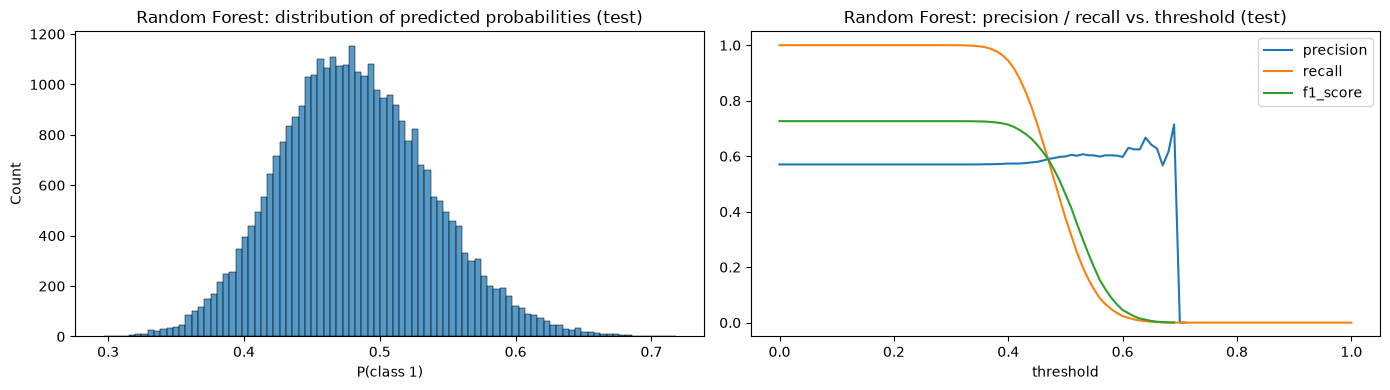

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(rf_proba_test, ax=axes[0])
axes[0].set_title('Random Forest: distribution of predicted probabilities (test)')
axes[0].set_xlabel('P(class 1)')

df_scores_rf.plot.line(x='threshold', y=['precision', 'recall', 'f1_score'], ax=axes[1],
                       title='Random Forest: precision / recall vs. threshold (test)')
plt.tight_layout()
plt.show()

### 4.2 Financial results of all Random Forest rules (0.55 … 0.65)

In [19]:
rf_rules = q1['sim'][q1['sim'].prediction.str.contains('rf_best_rule')].copy()
rf_rules['threshold'] = rf_rules.prediction.str.split('_').str[-1].astype(int) / 100
rf_rules = rf_rules.sort_values('threshold')

display(rf_rules[['prediction', 'threshold'] + SIM_COLUMNS[1:]].round(4))

,prediction,threshold,precision_test,sim1_count_investments,sim1_avg_investments_per_day,sim1_net_rev,sim1_capital,sim1_CAGR
10,pred10_rf_best_rule_55,0.55,0.6028,3756,6.0581,12983.5961,21000.0,1.1279
12,pred12_rf_best_rule_56,0.56,0.5986,2780,5.3462,9897.1316,21000.0,1.1013
13,pred13_rf_best_rule_57,0.57,0.6031,2086,4.8512,7593.3261,18000.0,1.0920
14,pred14_rf_best_rule_58,0.58,0.6030,1519,4.4941,5342.6268,18000.0,1.0671
15,pred15_rf_best_rule_59,0.59,0.6018,1090,4.3254,3753.3190,15000.0,1.0574
16,pred16_rf_best_rule_60,0.60,0.5973,745,3.9418,2531.1367,12000.0,1.0490
17,pred17_rf_best_rule_61,0.61,0.6303,522,3.6000,2118.4891,9000.0,1.0543
18,pred18_rf_best_rule_62,0.62,0.6246,349,3.4900,1266.4989,9000.0,1.0335
19,pred19_rf_best_rule_63,0.63,0.6245,229,3.0946,853.5840,9000.0,1.0229
20,pred20_rf_best_rule_64,0.64,0.6667,153,3.0600,650.3398,9000.0,1.0176


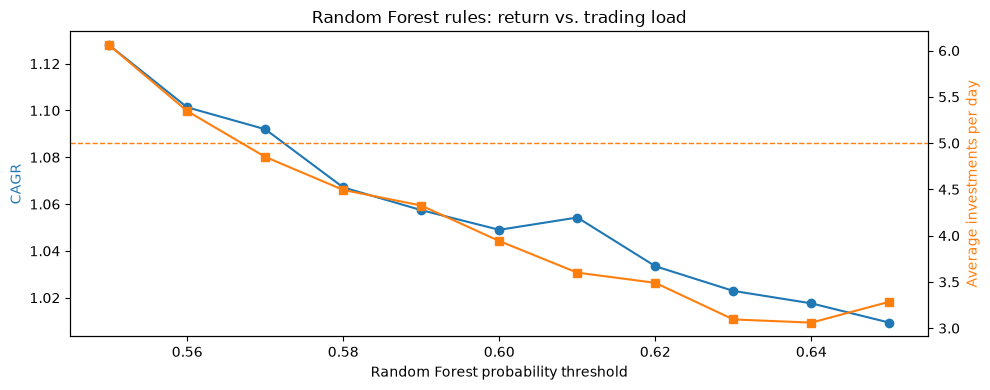

In [20]:
fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(rf_rules.threshold, rf_rules.sim1_CAGR, marker='o', color='tab:blue')
ax1.set_xlabel('Random Forest probability threshold')
ax1.set_ylabel('CAGR', color='tab:blue')

ax2 = ax1.twinx()
ax2.plot(rf_rules.threshold, rf_rules.sim1_avg_investments_per_day, marker='s', color='tab:orange')
ax2.axhline(5, color='tab:orange', linestyle='--', linewidth=1)
ax2.set_ylabel('Average investments per day', color='tab:orange')

plt.title('Random Forest rules: return vs. trading load')
plt.tight_layout()
plt.show()

In [21]:
efficient = rf_rules[rf_rules.sim1_avg_investments_per_day < 5].sort_values('sim1_CAGR', ascending=False)
if efficient.empty:
    raise ValueError('No Random Forest rule has fewer than 5 average investments per day - check the thresholds.')
second_best = efficient.iloc[0]

print(f"Q2 ANSWER: threshold = {second_best.threshold:.2f} ({second_best.prediction})")
print(f"           CAGR = {second_best.sim1_CAGR:.4f}, "
      f"avg investments per day = {second_best.sim1_avg_investments_per_day:.2f}, "
      f"trades on test = {int(second_best.sim1_count_investments)}")

Q2 ANSWER: threshold = 0.57 (pred13_rf_best_rule_57)
           CAGR = 1.0920, avg investments per day = 4.85, trades on test = 2086


## 5. Question 3 — Redefining the growth target

**Change:** `is_positive_growth_30d_future = 1` only if `growth_future_30d > 1.022`
(≈ the median 30-day growth), instead of `> 1`. Everything else is the original course setup (301 features).

Only the training target changes. The simulation still uses the real `growth_future_30d`,
so the financial evaluation is comparable with the baseline.

In [22]:
# distribution of 30-day future growth (test of the claims in the homework text)
df_check = df_full[df_full.Date >= '2000-01-01']
display(df_check['growth_future_30d'].describe(percentiles=[0.25, 0.5, 0.75]).round(4).to_frame().T)
print(f"Share of class 1 with threshold 1.000: {(df_check['growth_future_30d'] > 1).mean():.3f}")
print(f"Share of class 1 with threshold 1.022: {(df_check['growth_future_30d'] > 1.022).mean():.3f}")

,count,mean,std,min,25%,50%,75%,max
growth_future_30d,201302.0,1.0234,0.1156,0.2461,0.9612,1.0206,1.0822,5.1797


Share of class 1 with threshold 1.000: 0.590
Share of class 1 with threshold 1.022: 0.491


In [23]:
q3 = run_experiment('q3', CATEGORICAL_FULL, target_growth_threshold=1.022)
display(q3['sim'][SIM_COLUMNS].sort_values('sim1_CAGR', ascending=False).round(4))
bubble_chart(q3['sim'], 'Q3 (target: growth > 2.2%): CAGR vs. average investments per day')

=== Experiment: q3 ===
  Features: 301 (numerical 186 + dummies 115)
  Share of class 1 in the target: 0.491
  Decision Trees fitted (38s)
  Random Forest fitted (101s)
  Done in 105s


,prediction,precision_test,sim1_count_investments,sim1_avg_investments_per_day,sim1_net_rev,sim1_capital,sim1_CAGR
5,pred5_clf_10,0.4744,7337,8.0098,17508.1556,30000.0,1.1218
1,pred1_manual_prev_g1,0.4738,19158,18.4212,40815.7669,72000.0,1.1188
2,pred2_manual_prev_g1_and_snp,0.4672,15244,21.7151,30759.2942,75000.0,1.0897
7,pred7_clf_second_best,0.4803,10532,12.6739,22463.6087,57000.0,1.0866
3,pred3_manual_dgs10_5,0.4827,15910,31.9478,37541.8030,99000.0,1.0837
8,pred8_clf_second_best_rule_56,0.4717,10276,12.4860,20069.6483,54000.0,1.0822
9,pred9_clf_second_best_rule_66,0.4627,9746,13.4799,17329.7596,57000.0,1.0686
0,pred0_manual_cci,0.4691,921,1.8758,1655.1929,6000.0,1.0628
6,pred6_clf_4,0.5282,7209,30.8077,22563.9549,99000.0,1.0527
10,pred10_rf_best_rule_55,0.6491,171,1.9213,1269.7586,6000.0,1.0492


In [24]:
best_q3 = q3['sim'].sort_values('sim1_CAGR', ascending=False).iloc[0]
pred5_q3 = q3['sim'].set_index('prediction').loc['pred5_clf_10']

print(f"Best predictor by CAGR: {best_q3.prediction} (CAGR {best_q3.sim1_CAGR:.4f})")
print(f"Q3 ANSWER: number of trades for pred5_clf_10 = {int(pred5_q3.sim1_count_investments)} "
      f"(CAGR {pred5_q3.sim1_CAGR:.4f}, avg investments per day {pred5_q3.sim1_avg_investments_per_day:.2f})")
if RUN_BASELINE:
    b5 = baseline['sim'].set_index('prediction').loc['pred5_clf_10']
    print(f"           baseline pred5_clf_10: {int(b5.sim1_count_investments)} trades, CAGR {b5.sim1_CAGR:.4f}")

Best predictor by CAGR: pred5_clf_10 (CAGR 1.1218)
Q3 ANSWER: number of trades for pred5_clf_10 = 7337 (CAGR 1.1218, avg investments per day 8.01)
           baseline pred5_clf_10: 9861 trades, CAGR 1.1195


## 6. Summary of answers

In [25]:
summary = pd.DataFrame([
    {'question': 'Q1', 'answer': f"CAGR pred10_rf_best_rule_55 = {q1_row.sim1_CAGR:.4f}"},
    {'question': 'Q2', 'answer': f"threshold = {second_best.threshold:.2f} "
                                 f"(CAGR {second_best.sim1_CAGR:.4f}, {second_best.sim1_avg_investments_per_day:.2f} trades/day)"},
    {'question': 'Q3', 'answer': f"pred5_clf_10 trades = {int(pred5_q3.sim1_count_investments)}"},
])
display(summary)

,question,answer
0,Q1,CAGR pred10_rf_best_rule_55 = 1.1279
1,Q2,"threshold = 0.57 (CAGR 1.0920, 4.85 trades/day)"
2,Q3,pred5_clf_10 trades = 7337


## 7. Question 4 — My trading strategy (exploratory)

The `sim1` rule ("invest $100 in every positive prediction") has four weak points:
the number of trades is not controlled, the capital is estimated after the fact (Q75 of daily signals),
there is no risk control on single positions, and all choices (model depth, thresholds) were made by looking at the test period.

**Proposed strategy**

1. **Signal.** Use the Random Forest probability. Each day, rank the stocks with `proba ≥ 0.60`
   and keep at most the **top 3** by probability. This caps the load at 3 trades per day by design.
2. **Position sizing.** The portfolio is split into 30 daily "slots" (positions are held 30 trading days).
   Each day's slot is divided equally among that day's picks; unused slots stay in cash or an S&P 500 ETF.
   The capital is then known in advance instead of estimated.
3. **Concentration.** Do not open a new position in a ticker that already has an open position,
   so one stock cannot take several slots during a long uptrend.
4. **Risk.** Close a position early at −8% (stop-loss) or +15% (take-profit), to cut the left tail of the 30-day outcomes.
5. **Honest evaluation.** Choose the threshold and top-N on the validation period only, run the test period once,
   and compare the CAGR with buy-and-hold S&P 500 over the same years and with the same fees.

To implement it, `simulate_sim1()` would be replaced by a day-by-day loop over the test period that keeps a list of open positions,
checks stop-loss / take-profit on daily prices, and frees the slot when a position closes.

## 8. Notes

* **Bug in the original course notebook (section 2.1).** The Logistic Regression section runs
  `X_test = scaler.transform(X_test)`, so the later `clf_best.predict_proba(X_test)` / `rf_best.predict_proba(X_test)`
  and the `df_scores` threshold table are computed on *standardised* features with models trained on *raw* features.
  The simulation is not affected (it predicts on `X_all`, which is never scaled), but the threshold table there is not reliable.
  Here `X_test` is never scaled.
* **Optimistic results.** Tree depths, Random Forest parameters and decision thresholds were selected using precision
  or CAGR on the test period, so test results are in-sample with respect to these choices.
* **Survivorship bias.** The 33 stocks are today's large caps; companies that failed since 2000 are not in the data.
* **Simplified capital.** On the 25% busiest days there are more signals than the capital covers, but the simulation still counts them.
* **No benchmark.** The simulation does not compare the strategy with buy-and-hold S&P 500 over the same period.